Loaded 28 food items with 5 nutritional features.


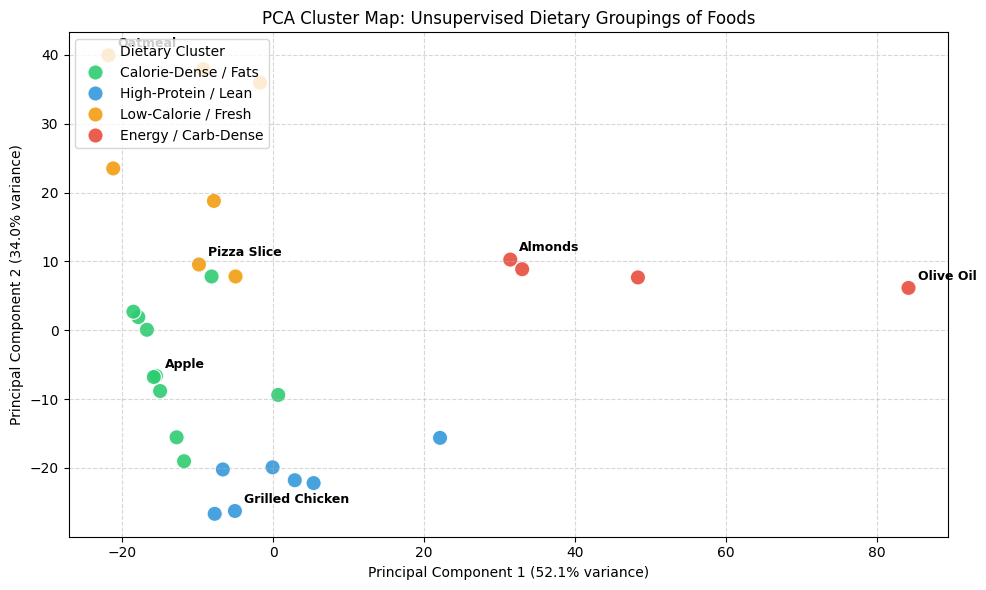


Model Performance Metrics:
  • R² Score (Variance Explained) : 0.8617
  • Root Mean Squared Error (RMSE): 70.56 kcal


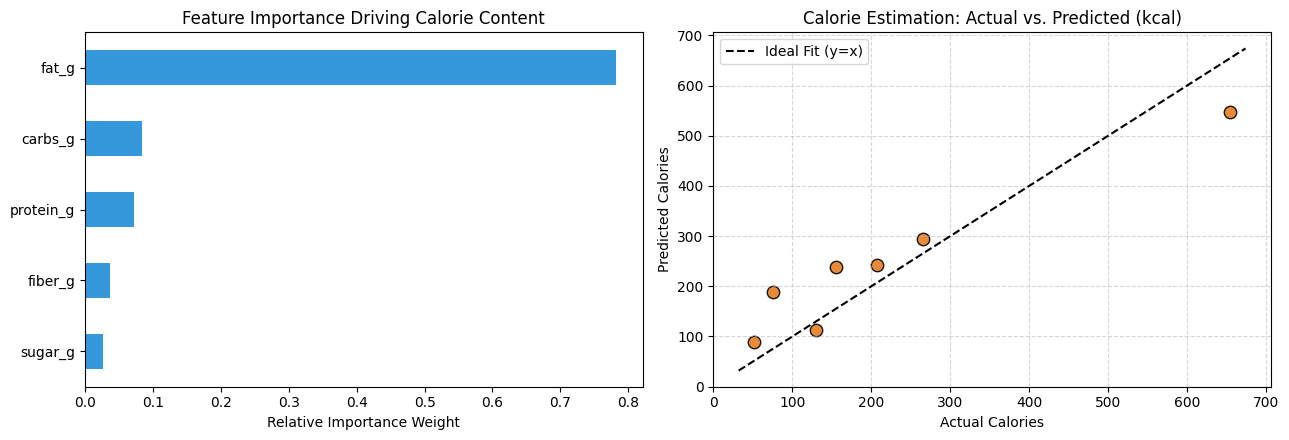


Demonstration Scorecard Output:


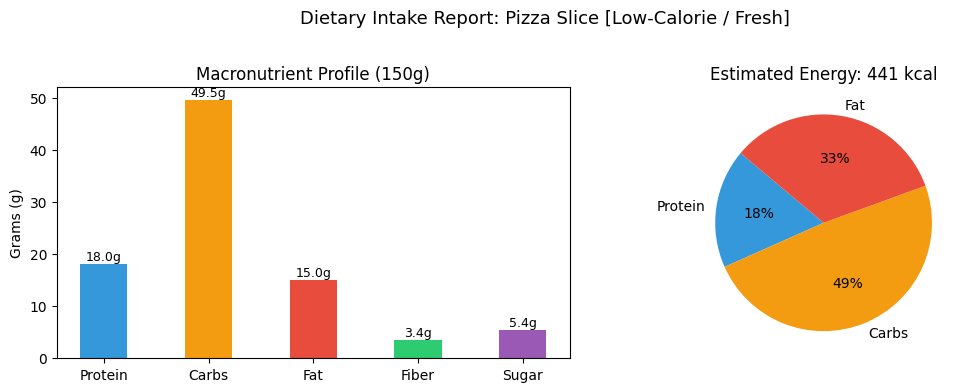

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


data = {
    "food_name": [
        "Apple", "Banana", "Orange", "Broccoli", "Spinach", "Avocado",
        "Grilled Chicken", "Salmon", "Boiled Egg", "Tofu", "Beef Steak", "Turkey Breast",
        "White Rice", "Oatmeal", "Brown Bread", "Boiled Potato", "Pasta",
        "Pizza Slice", "Cheeseburger", "French Fries", "Donut", "Ice Cream", "Chocolate Cake",
        "Almonds", "Peanut Butter", "Walnuts", "Olive Oil", "Cheddar Cheese"
    ],
    "category": [
        "Fruit/Veg", "Fruit/Veg", "Fruit/Veg", "Fruit/Veg", "Fruit/Veg", "Fruit/Veg",
        "Protein", "Protein", "Protein", "Protein", "Protein", "Protein",
        "Grains/Carbs", "Grains/Carbs", "Grains/Carbs", "Grains/Carbs", "Grains/Carbs",
        "Fast Food/Sweets", "Fast Food/Sweets", "Fast Food/Sweets", "Fast Food/Sweets", "Fast Food/Sweets", "Fast Food/Sweets",
        "Fats/Nuts", "Fats/Nuts", "Fats/Nuts", "Fats/Nuts", "Fats/Nuts"
    ],
    "protein_g": [0.3, 1.3, 0.9, 2.8, 2.9, 2.0, 31.0, 20.0, 13.0, 8.0, 26.0, 29.0, 2.7, 13.0, 9.0, 2.0, 5.0, 12.0, 15.0, 3.4, 4.0, 3.5, 4.0, 21.0, 25.0, 15.0, 0.0, 25.0],
    "carbs_g":   [14.0, 23.0, 12.0, 7.0, 3.6, 9.0, 0.0, 0.0, 1.1, 1.9, 0.0, 0.0, 28.0, 68.0, 49.0, 17.0, 25.0, 33.0, 30.0, 41.0, 49.0, 24.0, 50.0, 22.0, 20.0, 14.0, 0.0, 1.3],
    "fat_g":     [0.2, 0.3, 0.1, 0.4, 0.4, 15.0, 3.6, 13.0, 11.0, 4.8, 15.0, 1.0, 0.3, 7.0, 3.0, 0.1, 1.1, 10.0, 14.0, 15.0, 25.0, 11.0, 18.0, 49.0, 50.0, 65.0, 100.0, 33.0],
    "fiber_g":   [2.4, 2.6, 2.4, 2.6, 2.2, 7.0, 0.0, 0.0, 0.0, 0.9, 0.0, 0.0, 0.4, 10.0, 7.0, 2.2, 1.4, 2.3, 1.5, 3.8, 2.0, 0.7, 2.0, 12.0, 6.0, 7.0, 0.0, 0.0],
    "sugar_g":   [10.0, 12.0, 9.0, 1.7, 0.4, 0.7, 0.0, 0.0, 1.1, 0.5, 0.0, 0.0, 0.1, 1.0, 6.0, 0.8, 0.6, 3.6, 5.0, 0.3, 27.0, 21.0, 38.0, 4.4, 9.0, 2.6, 0.0, 0.5],
    "calories":  [52, 89, 47, 34, 23, 160, 165, 206, 155, 76, 250, 135, 130, 389, 247, 77, 131, 266, 295, 312, 452, 207, 371, 579, 588, 654, 884, 403]
}

df = pd.DataFrame(data)
feature_cols = ["protein_g", "carbs_g", "fat_g", "fiber_g", "sugar_g"]
X = df[feature_cols]
y = df["calories"]

print(f"Loaded {len(df)} food items with 5 nutritional features.")


# Discover 4 dietary clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X)

pca = PCA(n_components=2)
coords = pca.fit_transform(X)
df["pca1"] = coords[:, 0]
df["pca2"] = coords[:, 1]

cluster_names = {
    0: "Low-Calorie / Fresh",
    1: "High-Protein / Lean",
    2: "Energy / Carb-Dense",
    3: "Calorie-Dense / Fats"
}
df["cluster_label"] = df["cluster"].map(cluster_names)

plt.figure(figsize=(10, 6))
palette = ["#2ecc71", "#3498db", "#f39c12", "#e74c3c"]
sns.scatterplot(data=df, x="pca1", y="pca2", hue="cluster_label", palette=palette, s=120, alpha=0.9)

# Annotate sample foods on the scatter points
for i in [0, 6, 13, 17, 23, 26]:
    plt.text(df.loc[i, "pca1"] + 1.2, df.loc[i, "pca2"] + 1.2, df.loc[i, "food_name"], fontsize=9, fontweight="bold")

plt.title("PCA Cluster Map: Unsupervised Dietary Groupings of Foods", fontsize=12)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(title="Dietary Cluster", loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nModel Performance Metrics:")
print(f"  • R² Score (Variance Explained) : {r2:.4f}")
print(f"  • Root Mean Squared Error (RMSE): {rmse:.2f} kcal")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Feature Importance
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind="barh", ax=ax1, color="#3498db")
ax1.set_title("Feature Importance Driving Calorie Content")
ax1.set_xlabel("Relative Importance Weight")

# 2. Actual vs Predicted Calories
ax2.scatter(y_test, y_pred, color="#e67e22", s=80, edgecolors="k", alpha=0.9)
min_val = min(y_test.min(), y_pred.min()) - 20
max_val = max(y_test.max(), y_pred.max()) + 20
ax2.plot([min_val, max_val], [min_val, max_val], "k--", lw=1.5, label="Ideal Fit (y=x)")
ax2.set_title("Calorie Estimation: Actual vs. Predicted (kcal)")
ax2.set_xlabel("Actual Calories")
ax2.set_ylabel("Predicted Calories")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


def get_food_dietary_report(food_query, mass_grams=100):
    match = df[df["food_name"].str.lower() == food_query.lower()]
    if match.empty:
        print(f"Food '{food_query}' not found. Available options: {list(df['food_name'].values[:8])}...")
        return

    row = match.iloc[0]
    mult = mass_grams / 100.0

    # Model inference
    query_features = pd.DataFrame([row[feature_cols].values], columns=feature_cols)
    pred_cal = model.predict(query_features)[0] * mult

    fig, (ax_bar, ax_pie) = plt.subplots(1, 2, figsize=(11, 3.8))

    # Macronutrient Bar Chart
    macros = ["Protein", "Carbs", "Fat", "Fiber", "Sugar"]
    vals = [row["protein_g"] * mult, row["carbs_g"] * mult, row["fat_g"] * mult, row["fiber_g"] * mult, row["sugar_g"] * mult]
    colors = ["#3498db", "#f39c12", "#e74c3c", "#2ecc71", "#9b59b6"]

    ax_bar.bar(macros, vals, color=colors, width=0.45)
    ax_bar.set_ylabel("Grams (g)")
    ax_bar.set_title(f"Macronutrient Profile ({mass_grams}g)")
    for i, v in enumerate(vals):
        ax_bar.text(i, v + 0.8, f"{v:.1f}g", ha="center", fontsize=9)

    # Caloric Energy Breakdown (4 kcal/g protein, 4 kcal/g carbs, 9 kcal/g fat)
    cal_split = [(row["protein_g"] * 4) * mult, (row["carbs_g"] * 4) * mult, (row["fat_g"] * 9) * mult]
    ax_pie.pie(cal_split, labels=["Protein", "Carbs", "Fat"], autopct="%1.0f%%", colors=colors[:3], startangle=140)
    ax_pie.set_title(f"Estimated Energy: {pred_cal:.0f} kcal")

    plt.suptitle(f"Dietary Intake Report: {row['food_name']} [{row['cluster_label']}]", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

# Demonstrate dietary report on Pizza Slice (150g portion)
print("\nDemonstration Scorecard Output:")
get_food_dietary_report("Pizza Slice", mass_grams=150)